In [1]:
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator

In [2]:
generator = InterventionDatasetGenerator(
    function_generator="simplegp",
    num_variables=[3],
    sample_size=1000,
    batch_size=1,
    graph_type=["ER"],
    graph_degrees=[3],
    iterations_per_epoch=10,
)

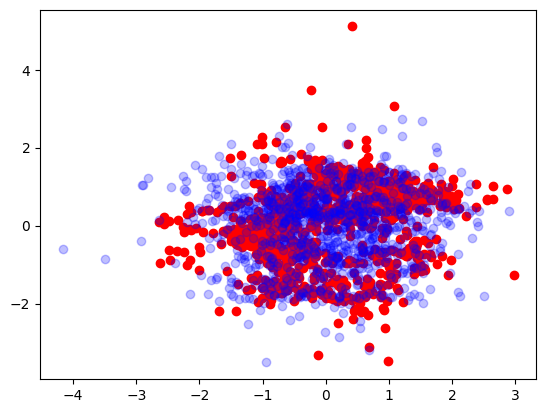

Causal graph: tensor([[0., 1., 1.],
        [0., 0., 0.],
        [0., 1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 2


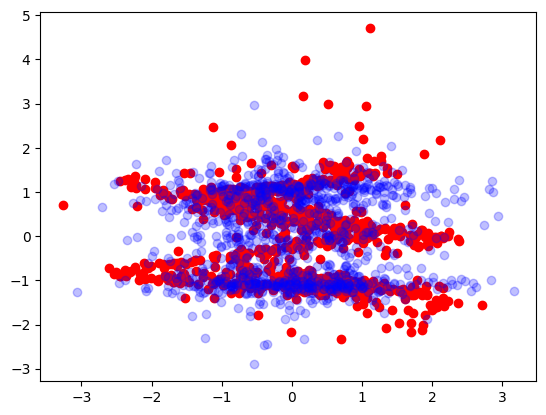

Causal graph: tensor([[0., 1., 1.],
        [0., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
Intervention: tensor(2)
Outcome: 1


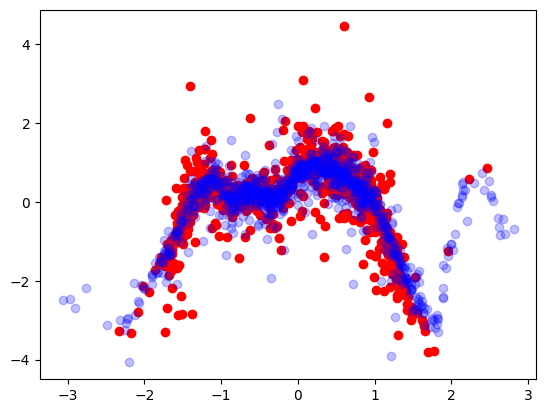

Causal graph: tensor([[0., 1., 0.],
        [0., 0., 0.],
        [1., 1., 0.]], dtype=torch.float64)
Intervention: tensor(2)
Outcome: 1


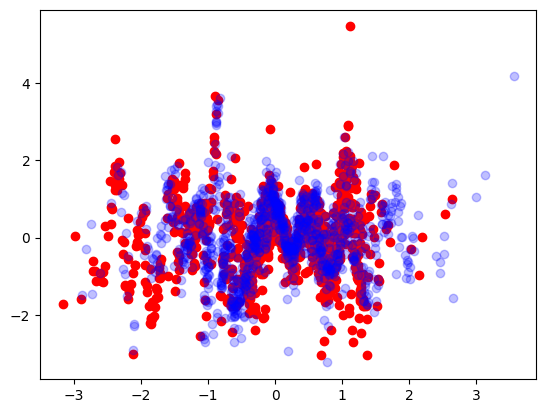

Causal graph: tensor([[0., 0., 1.],
        [1., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 2


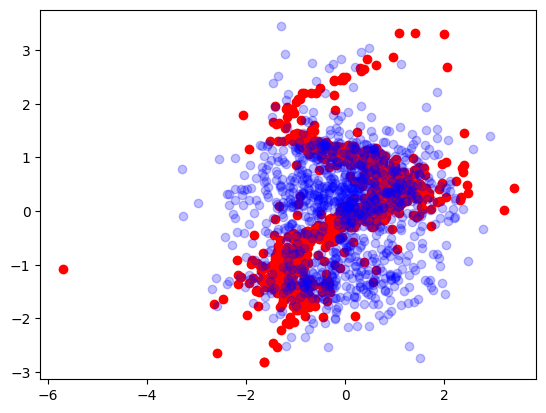

Causal graph: tensor([[0., 0., 0.],
        [1., 0., 0.],
        [1., 1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 2


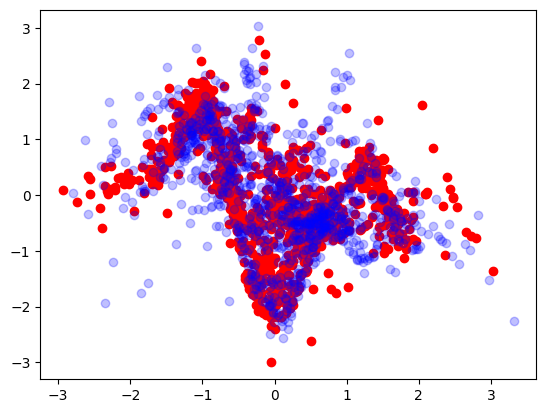

Causal graph: tensor([[0., 0., 0.],
        [1., 0., 0.],
        [1., 1., 0.]], dtype=torch.float64)
Intervention: tensor(1)
Outcome: 0


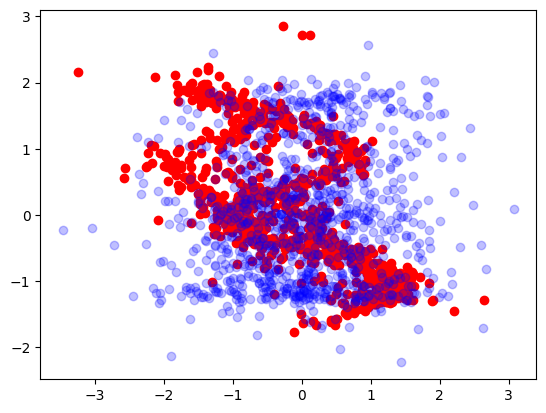

Causal graph: tensor([[0., 1., 1.],
        [0., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
Intervention: tensor(2)
Outcome: 1


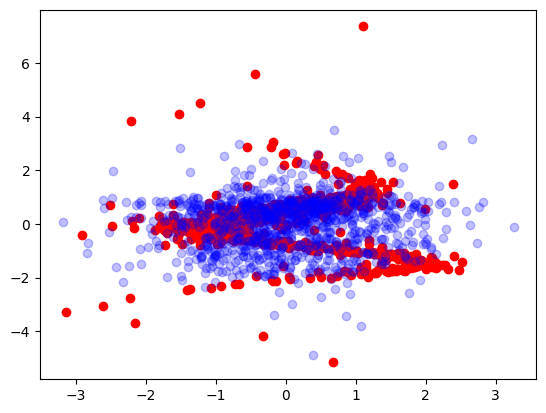

Causal graph: tensor([[0., 0., 1.],
        [1., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
Intervention: tensor(0)
Outcome: 1


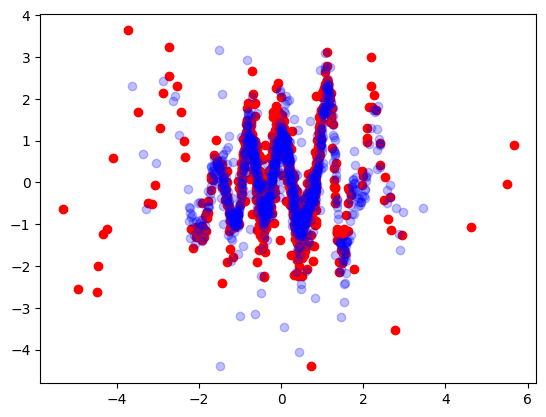

Causal graph: tensor([[0., 1., 0.],
        [0., 0., 0.],
        [1., 1., 0.]], dtype=torch.float64)
Intervention: tensor(2)
Outcome: 0


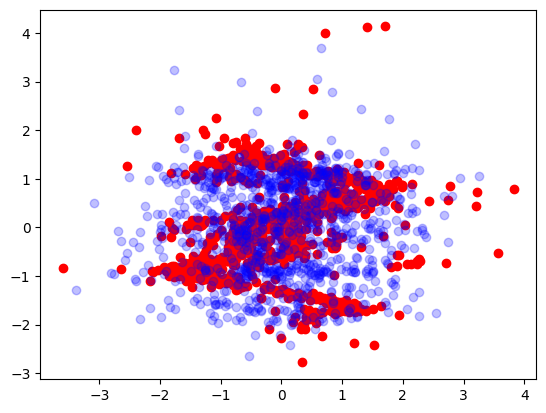

Causal graph: tensor([[0., 1., 1.],
        [0., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
Intervention: tensor(2)
Outcome: 1


<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks,
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(variable_counts, intvn_indices)

    plt.scatter(
        obs_data_array[0][:, intvn_indices[0]],
        obs_data_array[0][:, outcome_index[0]],
        c="r",
    )

    plt.scatter(
        int_data_array[0][:, intvn_indices[0]],
        int_data_array[0][:, outcome_index[0]],
        c="b",
        alpha=0.25,
    )
    plt.show()
    plt.clf()
    print("Causal graph:", causal_graphs_array[0])
    print("Intervention:", intvn_indices[0])
    print("Outcome:", outcome_index[0])

In [6]:
obs_data_array.mean(1)

tensor([[ 1.3912e-08, -8.1533e-08,  4.8144e-09]], dtype=torch.float64)

In [5]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import transformer_inference_split_withpadding


data_loader = DataLoader(
    generator,
    batch_size=None,
    collate_fn=transformer_inference_split_withpadding(
        cntxt_split=[0.2, 0.8], sample_size=1000
    ),
)


for idx, batch in enumerate(data_loader):
    (context, target, intvn_indices, outcome_indices, masks) = batch

    plt.scatter(context[0][:, 0], context[0][:, 1], c="r")
    plt.scatter(target[0][:, 0], target[0][:, 1], c="b", alpha=0.25)
    plt.show()
    plt.clf()
    print(intvn_indices[0])
    print(outcome_indices[0])

ValueError: too many values to unpack (expected 5)

In [ ]:
context.shape